In [31]:
from pathlib import Path
import os, sys

# Auto-set repo root (expects Data/ and predictions/ at root)
cwd = Path.cwd()
REPO_ROOT = None
for parent in [cwd, *cwd.parents]:
    if (parent / "Data").exists() and (parent / "predictions").exists():
        REPO_ROOT = parent
        break
if REPO_ROOT is None:
    REPO_ROOT = cwd
os.chdir(REPO_ROOT)

# Add notebook-local modules to import path
src_candidates = [
    REPO_ROOT / "notebooks",
    REPO_ROOT / "code_repository" / "notebooks",
]
for SRC in src_candidates:
    if SRC.exists() and str(SRC) not in sys.path:
        sys.path.insert(0, str(SRC))
        break
print(f"Working dir: {Path.cwd()}")


Working dir: /mnt/nas/PhD/Code/Ms_paint/code_repository


In [32]:
from analysis.plot_style import apply_style, save_figure, set_save_dir
FIGURE_ID = "figure2"
FIG_DIR = set_save_dir(REPO_ROOT, FIGURE_ID)
apply_style()


In [33]:
import analysis.figure2_helpers as figure2_helpers
from analysis.figure2_helpers import (
    plot_mic_by_moa_violin,
    plot_ecfp_embedding,
    plot_mic_by_moa,
    short_moa,
    moa_palette,
)


In [34]:
import pandas as pd
import numpy as np
# --- Import your modules ---
from data_processing.proteomics import prepare_proteomics_data, label_dict
from data_processing.chemistry import prepare_compound_data_from_excels, generate_mic_feature_matrix, generate_growth_curve_matrix, ChemicalRepresenter
from data_processing.cell_paint import CellPaintRepresenter
from data_processing.text_augmentation import augment_moa_descriptions, compute_llm_perplexities, generate_text_embeddings


In [35]:
y_labels = pd.read_pickle("Data/Base/y_labels.pkl")

In [36]:
MOA_ORDER_FIXED = ['Fatty acid',
 'Nitrofurans',
 'Folic acid',
 'Membrane',
 'RNA synth.',
 'LPS synth.',
 'DNA repl.',
 'Cell wall',
 'Protein syn.']
MOA_COLOR_MAP_FIXED = {'Fatty acid': '#264653',
 'Nitrofurans': '#287271',
 'Folic acid': '#2a9d8f',
 'Membrane': '#7fb48a',
 'RNA synth.': '#e9c46a',
 'LPS synth.': '#c6902e',
 'DNA repl.': '#f28e2b',
 'Cell wall': '#e76f51',
 'Protein syn.': '#d1495b'}
figure2_helpers.MOA_ORDER_FIXED = MOA_ORDER_FIXED
figure2_helpers.MOA_COLOR_MAP_FIXED = MOA_COLOR_MAP_FIXED

In [37]:
counts = y_labels.value_counts()

In [38]:
import os
compound_data_folder = "Data/"
compound_dict = prepare_compound_data_from_excels(
        growth_curve_file=os.path.join(compound_data_folder, "250808_compounds.xlsx"),
        mic_file=os.path.join(compound_data_folder, "250808_compounds.xlsx"),
        smiles_file=os.path.join(compound_data_folder, "250808_compounds.xlsx"),
        output_pickle_path=None
    )

{'Ampicillin (sodium)': 'JH0', 'Amoxicillin': 'JH1', 'Sulopenem': 'JH2', 'Cefodizime': 'JH3', 'Aztreonam': 'JH4', 'Doripenem': 'JH5', 'Imipenem (monohydrate)': 'JH6', 'Ertapenem (disodium)': 'JH7', 'Cefiderocol': 'JH8', 'Cefepime': 'JH9', 'Fosfomycin (calcium)': 'JH10', 'Retapamulin': 'JH11', 'Framycetin (sulfate)': 'JH12', 'Chloramphenicol': 'JH13', 'Tigecycline': 'JH14', 'Tetracycline': 'JH15', 'Azithromycin': 'JH16', 'Gentamicin sulfate': 'JH17', 'Eravacycline (dihydrochloride)': 'JH18', 'Apramycin (sulfate)': 'JH19', 'Kanamycin sulfate': 'JH55', 'Tobramycine': 'JH56', 'Sulfamonomethoxine': 'JH20', 'Sulfisoxazole': 'JH21', 'Sulfacetamide': 'JH22', 'Trimethoprim': 'JH23', 'Tetroxoprim': 'JH24', 'Sulfaguanidine': 'JH25', 'Sulphanilamide': 'JH57', 'Sulfadiazine': 'JH63', 'Gatifloxacin': 'JH26', 'Temafloxacin': 'JH27', 'Lascufloxacin': 'JH28', 'Ciprofloxacin': 'JH29', 'Levofloxacin': 'JH30', 'Nitrofurantoin': 'JH31', 'Gepotidacin': 'JH32', 'Nalidixic acid': 'JH33', 'Novobiocin': 'JH34',

In [39]:
df = pd.DataFrame(compound_dict).transpose()

In [40]:
mic_data = pd.read_pickle("Data/Base/X_mic.pkl")
gc = pd.read_pickle("Data/Base/X_gc.pkl")
ecfp_data = pd.read_pickle("Data/Base/X_ecfp.pkl")
y_labels = pd.read_pickle("Data/Base/y_labels.pkl")

In [41]:
ecfp_unique = ecfp_data.drop_duplicates()

In [42]:
ecfp_unique

,0,1,2,3,4,5,6,7,8,9,...,2038,2039,2040,2041,2042,2043,2044,2045,2046,2047
JH2_1,0,1,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
JH3_1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
JH5_1,1,1,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
JH6_1,0,1,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
JH7_1,0,1,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
JH8_1,0,0,0,0,0,1,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
JH9_1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
JH10_1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
JH12_1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
JH13_1,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [43]:
# ============================
# Shared style + helpers
# ============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter
from matplotlib.ticker import FormatStrFormatter
from analysis.plot_style import apply_style, style_axes

# Your fixed 9-color MoA palette (in order of class frequency mapping)
COLORS = ["#264653","#287271","#2a9d8f","#8ab17d",
          "#e9c46a","#efb366","#f4a261","#ee8959","#e76f51"]

def set_house_style():
    apply_style()

def set_house_style_minimal():
    apply_style()


/mnt/nas/PhD/Code/Ms_paint/code_repository/notebooks/analysis/figure2_helpers.py:349: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/mnt/nas/PhD/Code/Ms_paint/code_repository/notebooks/analysis/figure2_helpers.py:349: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/opt/conda/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


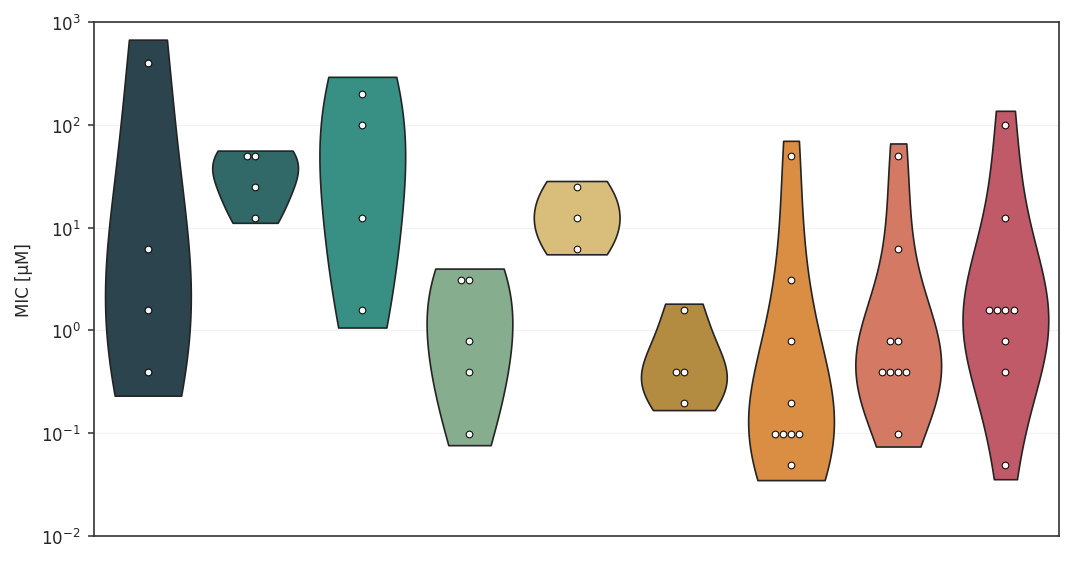

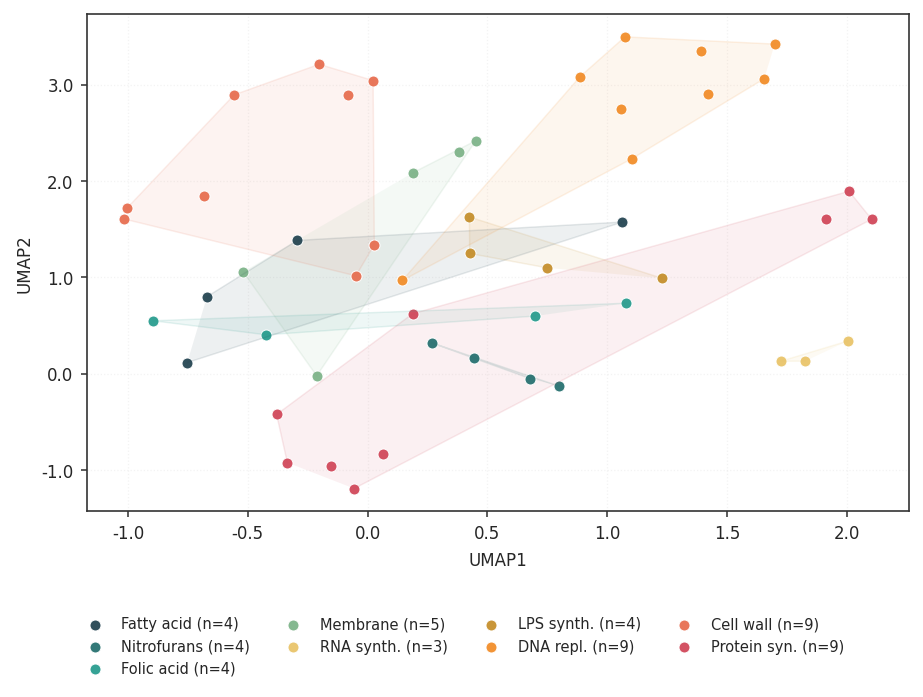

In [44]:
# MIC panel (2B)
mic_tidy = plot_mic_by_moa_violin(
    mic_data=mic_data,
    y_labels=y_labels,
    ecfp_unique=ecfp_unique,
    label_col=None,          # set if y_labels is a DataFrame
    thresh=0.1,
    title="",
    savepath="figures/figure2B_mic_by_moa"
)

# Structural panel (2C)
emb_df = plot_ecfp_embedding(
    ecfp_unique=ecfp_unique,
    y_labels=y_labels,
    label_col=None,          # set if needed
    use_umap=True,
    draw_hulls=True,
    show_counts_in_legend=True,
    title="",
    savepath="figures/figure2C_structural_space"
)


In [45]:
proteomics_data = pd.read_pickle("Data/Base/X_proteomics.pkl")

In [46]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def _base_compound_id(idx: pd.Index) -> pd.Index:
    # Strip trailing _digit replicate suffix if present (e.g., JH2_1 -> JH2)
    def strip(x: str) -> str:
        m = re.match(r"^(.*)_(\d+)$", str(x))
        return m.group(1) if m else str(x)
    return pd.Index([strip(i) for i in idx], name="compound")

def plot_proteomics_embedding(
    proteomics_data: pd.DataFrame,
    y_labels: pd.Series | pd.DataFrame,
    label_col: str | None = None,
    replicate_mode: str = "all",    # "all" | "median" | "first"
    use_umap: bool = True,
    draw_hulls: bool = True,
    show_counts_in_legend: bool = True,
    title: str | None = "2D  Proteomic response space (UMAP)",
    savepath: str | Path | None = "figures/figure2D_proteomics_space",
    random_state: int = 42,
):
    # ---------- style ----------
    set_house_style_minimal()

    # ---------- labels ----------
    if isinstance(y_labels, pd.DataFrame):
        if label_col is None:
            for cand in ["mode_of_action","moa","label","y"]:
                if cand in y_labels.columns:
                    label_col = cand; break
            if label_col is None:
                raise ValueError("Set `label_col` to the MoA column in y_labels.")
        y_series = y_labels[label_col].astype(str)
    else:
        y_series = y_labels.astype(str)

    # ---------- replicate handling ----------
    # Make a compound ID column from the index (strip _rep)
    compounds = _base_compound_id(proteomics_data.index)
    X = proteomics_data.copy()
    X.insert(0, "_compound", compounds)

    if replicate_mode == "median":
        # collapse replicates by compound (median across replicates, feature-wise)
        Xg = X.groupby("_compound").median(numeric_only=True)
        Xg.index.name = None
        y_comp = _base_compound_id(y_series.index)
        y_series2 = pd.Series(y_series.values, index=y_comp, name=y_series.name)
        # one label per compound (mode); if multiple MoAs per compound, take the first
        y_mode = y_series2.groupby(level=0).agg(lambda s: s.mode().iloc[0] if not s.mode().empty else s.iloc[0])
        # align
        common = Xg.index.intersection(y_mode.index)
        X_mat = Xg.loc[common]
        y_vec = y_mode.loc[common]
        marker_alpha = 0.95
        marker_size = 28
    elif replicate_mode == "first":
        # keep only the first replicate per compound
        first_rows = X.groupby("_compound").head(1).set_index("_compound")
        y_comp = _base_compound_id(y_series.index)
        y_series2 = pd.Series(y_series.values, index=y_comp, name=y_series.name)
        # align
        common = first_rows.index.intersection(y_series2.index)
        X_mat = first_rows.loc[common]
        y_vec = y_series2.loc[common]
        marker_alpha = 0.95
        marker_size = 28
    else:
        # plot all replicates
        X = X.set_index("_compound", append=True)  # multiindex: (orig_row, compound)
        # labels: map each orig_row to its label, fallback via compound if needed
        y_series2 = y_series.reindex(proteomics_data.index)
        # align by original index
        X_mat = proteomics_data.loc[y_series2.index]
        y_vec = y_series2
        marker_alpha = 0.8
        marker_size = 22

    # ---------- scale features (z-score per protein) ----------
    scaler = StandardScaler(with_mean=True, with_std=True)
    X_scaled = scaler.fit_transform(np.asarray(X_mat, dtype=float))

    # ---------- embed ----------
    method = "UMAP"
    try:
        if use_umap:
            import umap
            reducer = umap.UMAP(n_neighbors=50, min_dist=0.5, random_state=random_state, metric="euclidean")
            emb = reducer.fit_transform(X_scaled)
        else:
            raise ImportError
    except Exception:
        method = "PCA"
        reducer = PCA(n_components=2, random_state=random_state)
        emb = reducer.fit_transform(X_scaled)

    plot_df = pd.DataFrame(emb, columns=[f"{method}1", f"{method}2"], index=X_mat.index)
    plot_df["MoA"] = y_vec.values
    plot_df["MoA_short"] = plot_df["MoA"].map(short_moa)

    # ---------- order & palette ----------
    counts = Counter(plot_df["MoA_short"])
    moa_order = [m for m, _ in sorted(counts.items(), key=lambda x: x[1], reverse=True)]
    pal = moa_palette(moa_order)

    # ---------- optional hulls ----------
    try:
        from scipy.spatial import ConvexHull
        HAS_SCIPY = True
    except Exception:
        HAS_SCIPY = False

    def draw_convex_hull(ax, x, y, color, alpha=0.08, lw=0.7):
        if (not HAS_SCIPY) or len(x) < 3:
            return
        pts = np.column_stack([x, y])
        try:
            hull = ConvexHull(pts)
            poly = pts[hull.vertices]
            ax.fill(poly[:,0], poly[:,1], color=color, alpha=alpha, edgecolor="none")
            ax.plot(poly[:,0], poly[:,1], color=color, lw=lw, alpha=alpha*1.5)
        except Exception:
            pass

    # ---------- plot ----------
    fig, ax = plt.subplots(figsize=(6.8, 5.0))

    if draw_hulls:
        for moa in moa_order:
            sub = plot_df.loc[plot_df["MoA_short"] == moa]
            draw_convex_hull(ax, sub[f"{method}1"].values, sub[f"{method}2"].values, pal[moa])

    for moa in moa_order:
        sub = plot_df.loc[plot_df["MoA_short"] == moa]
        label = f"{moa} (n={len(sub)})" if show_counts_in_legend else moa
        ax.scatter(
            sub[f"{method}1"], sub[f"{method}2"],
            s=marker_size, c=[pal[moa]],
            edgecolors="white", linewidths=0.5, alpha=marker_alpha, label=label, zorder=3
        )

    ax.set_xlabel(f"{method}1")
    ax.set_ylabel(f"{method}2")
    title = title
    ax.set_title(title)
    ax.grid(True, linestyle=":", alpha=0.3)

    # ticks only on bottom/left, full box shown
    ax.tick_params(axis="both", which="both",
                   direction="out", length=3, width=0.8, color="0.25",
                   bottom=True, top=False, left=True, right=False)
    ax.margins(x=0.05, y=0.05)
    for s in ["left", "right", "top", "bottom"]:
        ax.spines[s].set_visible(True)
        ax.spines[s].set_linewidth(0.8)
        ax.spines[s].set_color("0.2")

    # compact legend at bottom
    handles, labels = ax.get_legend_handles_labels()
    ncols = 4 if len(labels) <= 12 else 5
    #fig.legend(handles, labels, loc="lower center", ncol=ncols, frameon=False,
    #           bbox_to_anchor=(0.5, -0.06))
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.22)

    if savepath:
        out = Path(savepath)
        out.parent.mkdir(parents=True, exist_ok=True)
        save_figure(fig, out.with_suffix(".png"), dpi=300, bbox_inches="tight")
        save_figure(fig, out.with_suffix(".pdf"), dpi=300, bbox_inches="tight")

    plt.show()
    return plot_df


/opt/conda/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


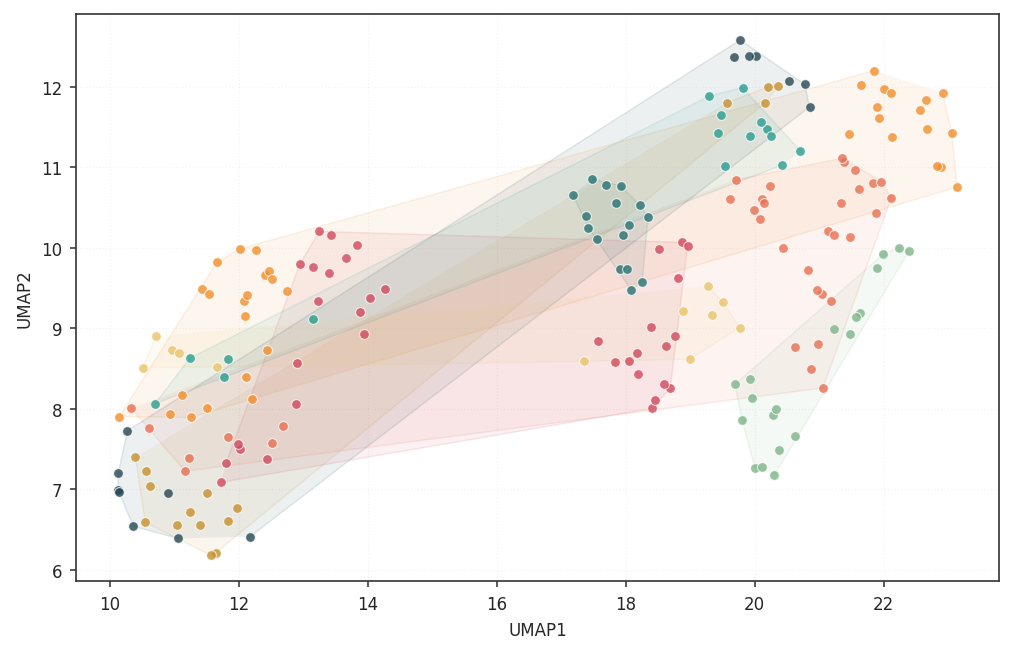

/opt/conda/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


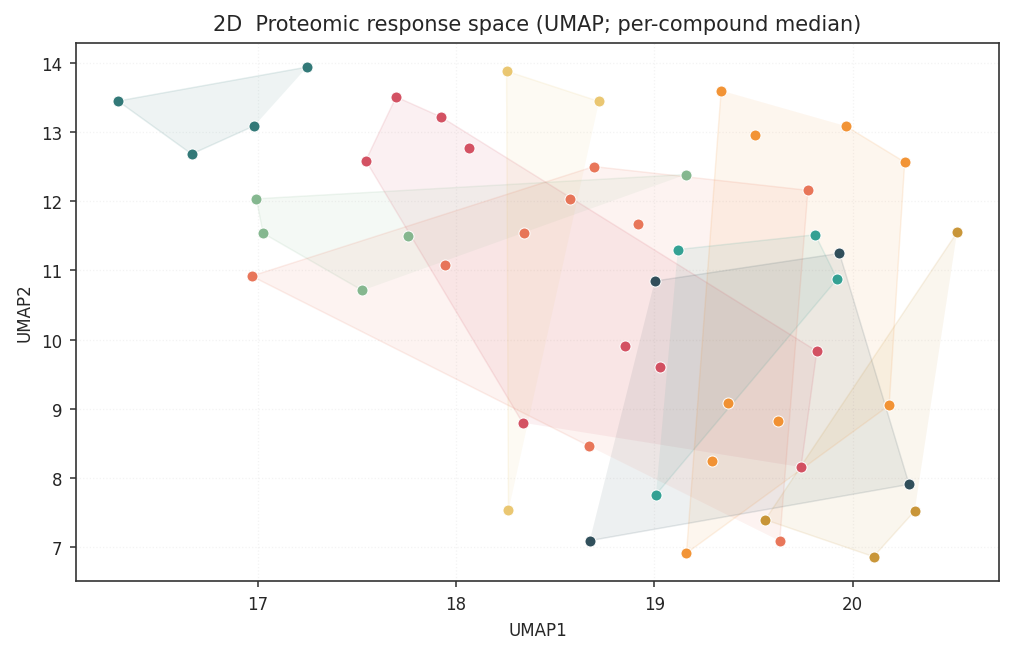

In [47]:
# A) Show ALL replicates (lighter alpha, smaller markers)
plot_df_all = plot_proteomics_embedding(
    proteomics_data=proteomics_data,
    y_labels=y_labels,
    label_col=None,              # set if y_labels is a DataFrame
    replicate_mode="all",
    use_umap=True,
    title="",
    savepath="figures/figure2D_proteomics_space_all"
)

# B) Collapse to one point per compound (median across replicates)
plot_df_med = plot_proteomics_embedding(
    proteomics_data=proteomics_data,
    y_labels=y_labels,
    label_col=None,
    replicate_mode="median",
    use_umap=True,
    title="2D  Proteomic response space (UMAP; per-compound median)",
    savepath="figures/figure2D_proteomics_space_median"
)


In [48]:
# Assume this is your UMAP embedding DataFrame
coords = plot_df_all[["UMAP1", "UMAP2"]].values
from sklearn.cluster import KMeans
import numpy as np
# Cluster into 3 groups
kmeans = KMeans(n_clusters=3, random_state=42)
plot_df_all["cluster"] = kmeans.fit_predict(coords)

In [49]:
for i, sub in plot_df_all.groupby("cluster"):
    print(f"\n--- Cluster {i} ({len(sub)} samples) ---")
    print(sub.index.tolist())



--- Cluster 0 (70 samples) ---
['JH3_1', 'JH3_2', 'JH3_3', 'JH3_4', 'JH6_1', 'JH6_2', 'JH6_3', 'JH6_4', 'JH7_1', 'JH7_2', 'JH7_3', 'JH7_4', 'JH8_1', 'JH8_2', 'JH8_3', 'JH8_4', 'JH9_1', 'JH9_2', 'JH9_3', 'JH9_4', 'JH10_1', 'JH10_2', 'JH10_3', 'JH10_4', 'JH20_1', 'JH20_2', 'JH20_3', 'JH20_4', 'JH21_1', 'JH21_2', 'JH21_3', 'JH21_4', 'JH23_2', 'JH23_3', 'JH23_4', 'JH26_1', 'JH26_2', 'JH26_3', 'JH26_4', 'JH29_1', 'JH29_2', 'JH29_3', 'JH29_4', 'JH32_1', 'JH32_2', 'JH32_3', 'JH32_4', 'JH33_1', 'JH33_2', 'JH33_3', 'JH33_4', 'JH42_2', 'JH42_3', 'JH42_4', 'JH46_1', 'JH46_2', 'JH46_3', 'JH46_4', 'JH47_1', 'JH47_2', 'JH47_3', 'JH47_4', 'JH61_1', 'JH61_2', 'JH61_3', 'JH61_4', 'JH62_1', 'JH62_2', 'JH62_3', 'JH62_4']

--- Cluster 1 (76 samples) ---
['JH2_1', 'JH2_2', 'JH2_3', 'JH2_4', 'JH5_1', 'JH5_3', 'JH5_4', 'JH13_1', 'JH13_2', 'JH13_3', 'JH13_4', 'JH16_1', 'JH16_2', 'JH16_3', 'JH17_1', 'JH17_2', 'JH17_3', 'JH17_4', 'JH23_1', 'JH24_1', 'JH24_2', 'JH24_3', 'JH24_4', 'JH27_1', 'JH27_2', 'JH27_3', '

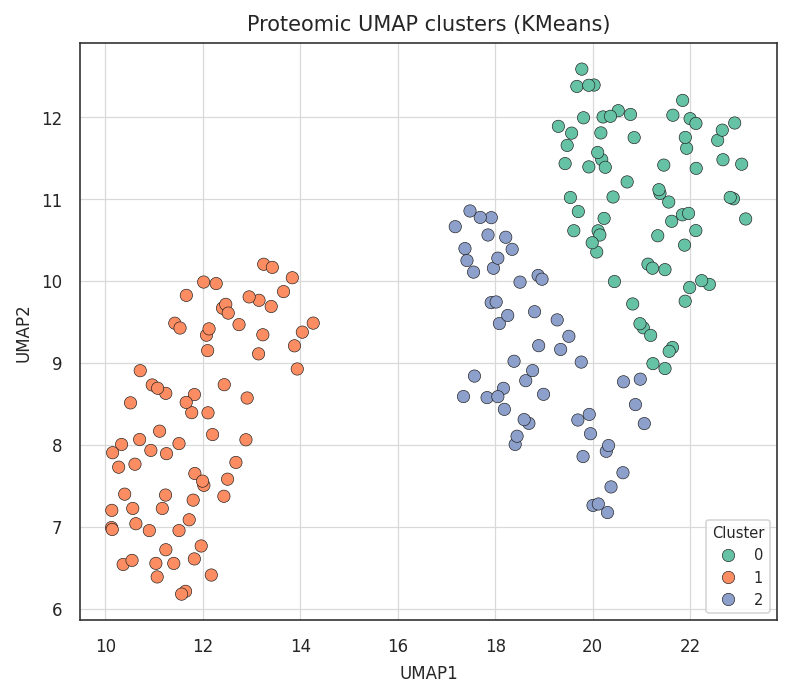

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=plot_df_all, x="UMAP1", y="UMAP2",
    hue="cluster", palette="Set2", s=35, edgecolor="k", linewidth=0.3
)
plt.title("Proteomic UMAP clusters (KMeans)")
plt.legend(title="Cluster", loc="lower right")
plt.show()


In [51]:
import re
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# ---------------------------------------------------
# 1) Parse the schedule text into a tidy metadata table
# ---------------------------------------------------
def parse_schedule(schedule_text: str) -> pd.DataFrame:
    """
    Returns a DataFrame with index=sample_id and columns:
    ['date','operator','batch','raw_line'].
    - date: 'YYMMDD' as string (e.g., '241112')
    - operator: 'DS' or 'LE'
    - batch: 'YYMMDD_OPERATOR'
    """
    current_date = None
    current_operator = None
    rows = []

    # helpers
    date_pat = re.compile(r'^\s*(\d{6})\b')          # e.g., 241112
    op_pat   = re.compile(r'^\s*(DS|LE)\b')          # DS or LE at start
    # First token that looks like an ID with at least one underscore (captures things like JH2_1, DMSO_1, Amp_1, 0,1_HCL_1)
    id_pat   = re.compile(r'\b[^\s\t]+_[^\s\t]+\b')

    for line in schedule_text.splitlines():
        raw = line.rstrip("\n")
        if not raw.strip():
            continue

        # date line?
        m_date = date_pat.match(raw)
        if m_date:
            current_date = m_date.group(1)
            continue

        # operator line?
        m_op = op_pat.match(raw)
        if m_op:
            current_operator = m_op.group(1)

        # try to find a sample id on the line
        # strategy: split by tabs, drop empties, search tokens for the first token that looks like "xxx_yyy"
        toks = [t for t in re.split(r'\t+', raw.strip()) if t != ""]
        sample_id = None

        # fast path: if operator is present first, sample is usually at toks[2]
        if current_operator and len(toks) >= 3 and toks[0] == current_operator:
            cand = toks[2]
            if id_pat.search(cand):
                sample_id = cand

        # fallback: scan tokens for first "xxx_yyy" pattern
        if sample_id is None:
            for t in toks:
                if id_pat.search(t):
                    sample_id = t
                    break

        if sample_id is None:
            # No sample on this line; skip
            continue

        # record a row
        rows.append({
            "sample": sample_id,
            "date": current_date,
            "operator": current_operator,
            "raw_line": raw
        })

    if not rows:
        return pd.DataFrame(columns=["date","operator","batch","raw_line"])

    meta = pd.DataFrame(rows).drop_duplicates("sample").set_index("sample")
    # batch label
    meta["batch"] = meta.apply(
        lambda r: f"{r['date']}_{r['operator']}" if pd.notna(r['date']) and pd.notna(r['operator']) else None,
        axis=1
    )
    return meta[["date","operator","batch","raw_line"]]

# Example usage:
# schedule_text = """<<< paste the entire block here >>>"""
# meta_df = parse_schedule(schedule_text)
# display(meta_df.head())

# ---------------------------------------------------
# 2) Join with UMAP embedding and cluster the points
# ---------------------------------------------------
def cluster_umap_and_compare(plot_df_all: pd.DataFrame,
                             meta_df: pd.DataFrame,
                             n_clusters: int = 3,
                             random_state: int = 42):
    """
    plot_df_all: DataFrame with columns ['UMAP1','UMAP2'] and index = sample/replicate IDs.
    meta_df:     from parse_schedule(), index = sample/replicate IDs.
    """
    # left join to keep only points present in the embedding
    joined = plot_df_all.join(meta_df, how="left")

    # KMeans on UMAP coords
    coords = joined[["UMAP1","UMAP2"]].to_numpy()
    kmeans = KMeans(n_clusters=n_clusters, random_state=random_state)
    joined["cluster"] = kmeans.fit_predict(coords)

    # --- print quick summaries ---
    print("\nCounts per inferred cluster:")
    print(joined["cluster"].value_counts().sort_index(), "\n")

    # Contingency: cluster vs. operator
    if "operator" in joined.columns:
        print("Contingency: cluster × operator")
        print(pd.crosstab(joined["cluster"], joined["operator"]), "\n")

    # Contingency: cluster vs. batch (date_operator)
    if "batch" in joined.columns:
        ct = pd.crosstab(joined["cluster"], joined["batch"])
        print("Contingency: cluster × batch")
        print(ct, "\n")

    # Optionally compute ARI vs. operator (requires encoding operator to ints)
    if "operator" in joined.columns and joined["operator"].notna().any():
        op_encoded = joined["operator"].astype("category").cat.codes.to_numpy()
        ari = adjusted_rand_score(op_encoded, joined["cluster"].to_numpy())
        print(f"Adjusted Rand Index (clusters vs operator): {ari:.3f}")

    return joined

# ---------------------------------------------------
# 3) (Optional) Quick QC plot colored by batch or operator
# ---------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns

def plot_umap_by_batch(joined: pd.DataFrame, color_by: str = "batch", title: str = None):
    title = title or f"Proteomic UMAP colored by {color_by}"
    plt.figure(figsize=(7, 5))
    sns.scatterplot(
        data=joined, x="UMAP1", y="UMAP2",
        hue=color_by, s=35, linewidth=0.3, edgecolor="k", palette="tab20"
    )
    plt.title(title)
    plt.grid(True, linestyle=":", alpha=0.3)
    ax = plt.gca()
    ax.tick_params(axis="both", which="both", direction="out", length=3, width=0.8, color="0.25",
                   bottom=True, top=False, left=True, right=False)
    for s in ["left","right","top","bottom"]:
        ax.spines[s].set_visible(True)
        ax.spines[s].set_linewidth(0.8)
        ax.spines[s].set_color("0.2")
    plt.tight_layout()
    plt.show()



Counts per inferred cluster:
cluster
0    70
1    76
2    54
Name: count, dtype: int64 

Contingency: cluster × operator
operator  DS  LE
cluster         
0         64   0
1          1  73
2         50   0 

Contingency: cluster × batch
batch    241112_LE  241114_LE  241122_LE  241126_LE  241203_LE  241210_LE  \
cluster                                                                     
0                0          0          0          0          0          0   
1               12         12          7         20         12         10   
2                0          0          0          0          0          0   

batch    250210_DS  250217_DS  250219_DS  250304_DS  250415_DS  250422_DS  \
cluster                                                                     
0               16          8          8          8          8         16   
1                0          1          0          0          0          0   
2                0         11          7         12          4      

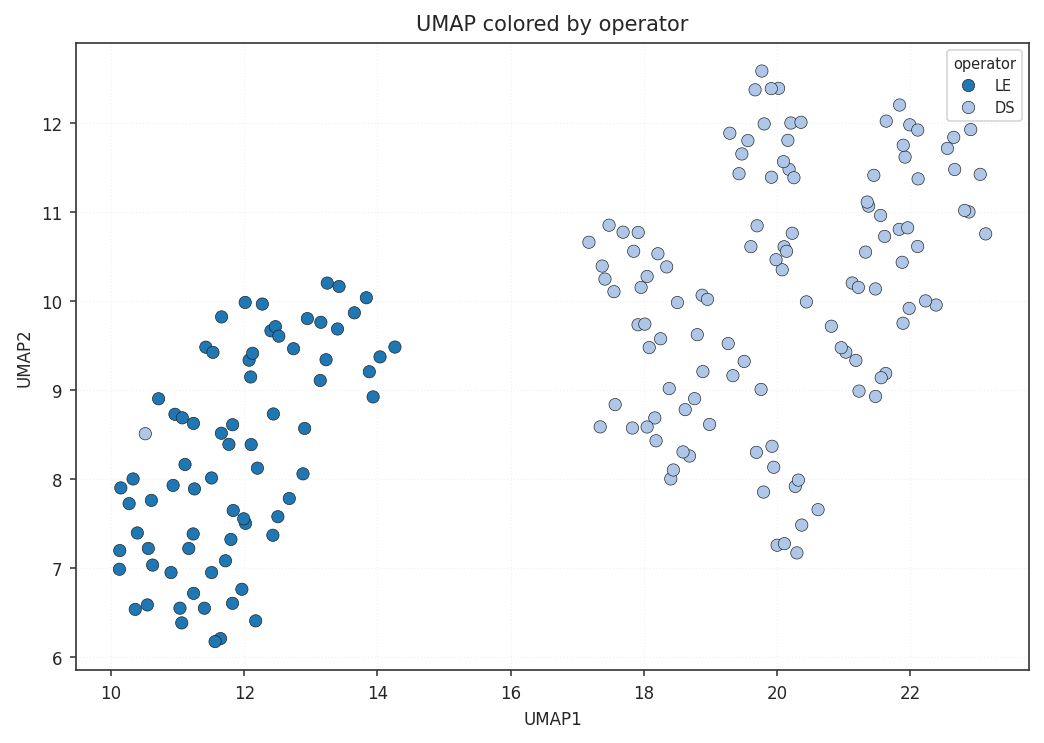

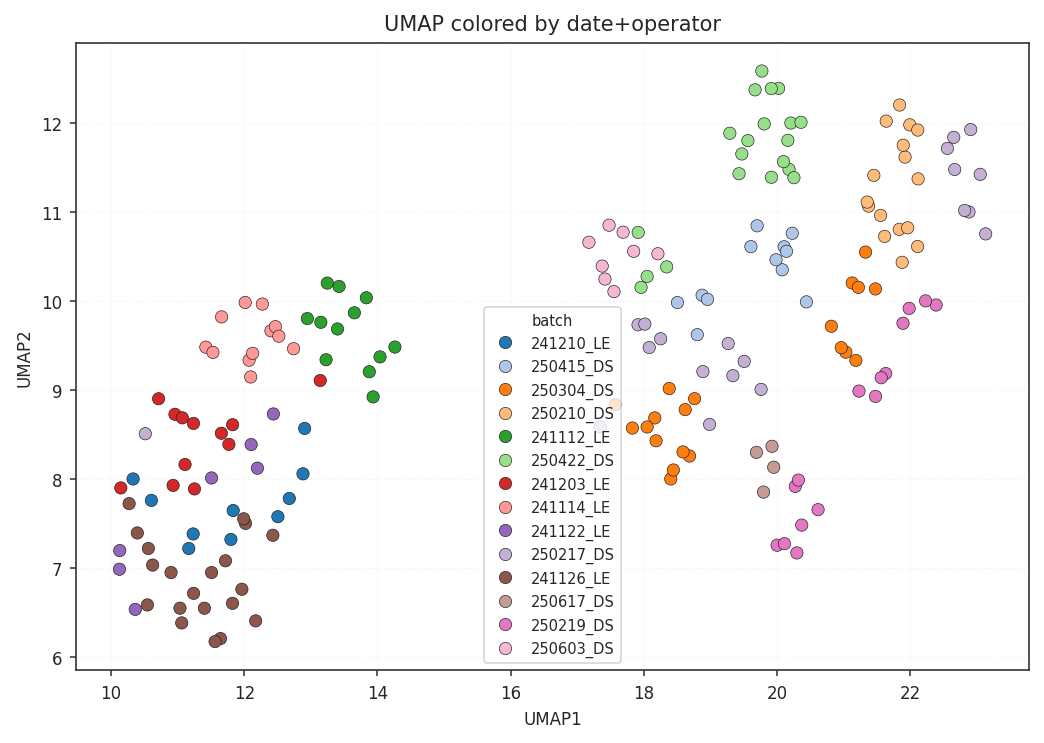

In [52]:
# 1) Parse the schedule
schedule_text = """241112							5	1	
LE	1	JH13_1	62,5	312,5	10 mM	31,25		5*MIC	bacteriostatic after 2h
	2	JH13_2	62,5	312,5	10 mM	31,25		5*MIC	
	3	JH13_3	62,5	312,5	10 mM	31,25		5*MIC	
	4	JH13_4	62,5	312,5	10 mM	31,25		5*MIC	
	5	JH17_1	1,95	9,75				5*MIC	bacteriostatic after 2h
	6	JH17_2	1,95	9,75				5*MIC	
	7	JH17_3	1,95	9,75				5*MIC	
	8	JH17_4	1,95	9,75				5*MIC	
	9	JH55_1	7,80	39,00	10 mM	3,90		5*MIC	bacteriostatic after 2h
	10	JH55_2	7,80	39,00	10 mM	3,90		5*MIC	
	11	JH55_3	7,80	39,00	10 mM	3,90		5*MIC	
	12	JH55_4	7,80	39,00	10 mM	3,90		5*MIC	
	13	DMSO_1		31,25				max vol	(D)
	14	DMSO_2		31,25				max vol	
	15	DMSO_3		31,25				max vol	
	16	DMSO_4		31,25				max vol	
241114							5	1	
LE	1	JH27_1	0,78	3,9				5*MIC	bacteriostatic after 7-24h
	2	JH27_2	0,78	3,9				5*MIC	
	3	JH27_3	0,78	3,9				5*MIC	
	4	JH27_4	0,78	3,9				5*MIC	
	5	JH35_1	12,5	62,5	10 mM	6,25		5*MIC	bacteriostatic after 7-24h
	6	JH35_2	12,5	62,5	10 mM	6,25		5*MIC	
	7	JH35_3	12,5	62,5	10 mM	6,25		5*MIC	
	8	JH35_4	12,5	62,5	10 mM	6,25		5*MIC	
	9	JH36_1	0,39	1,95				5*MIC	should be similar in growth compared to JH27 and JH35
	10	JH36_2	0,39	1,95				5*MIC	
	11	JH36_3	0,39	1,95				5*MIC	
	12	JH36_4	0,39	1,95				5*MIC	
	13	DMSO_1 °		6,25				max vol	(DP)
	14	DMSO_2 °		6,25				max vol	
	15	DMSO_3 °		6,25				max vol	
	16	DMSO_4 °		6,25				max vol	
	17	DMSO_HCL_1		3,9				vol JH27	0,016 M  HCL in DMSO
	18	DMSO_HCL_2		3,9				vol JH27	(H)
	19	DMSO_HCL_3		3,9				vol JH27	
	20	DMSO_HCL_4		3,9				vol JH27	
241122							5	1	
LE	1	JH28_1	0,39	1,95				5*MIC	bacteriostatic after 24h
	2	JH28_2	0,39	1,95				5*MIC	
	3	JH28_3	0,39	1,95				5*MIC	
	4	JH28_4	0,39	1,95				5*MIC	
	9	JH41_1	200,00	1000,00	10 mM	100,00		1*MIC	bacteriostatic after 24h
	10	JH41_2	200,00	1000,00	10 mM	100,00		1*MIC	
	11	JH41_3	200,00	1000,00	10 mM	100,00		1*MIC	
	12	JH41_4	200,00	1000,00	10 mM	100,00		1*MIC	
	17	DMSO_1				100,00		max vol	(DA)
	18	DMSO_2				100,00		max vol	
	19	DMSO_3				100,00		max vol	
	20	DMSO_4				100,00		max vol	
241126							5	1	
LE	1	JH40_1	15,5	77,5	10 mM	7,75		50*MIC	bacteriostatic after 24h
	2	JH40_2	15,5	77,5	10 mM	7,75		50*MIC	
	3	JH40_3	15,5	77,5	10 mM	7,75		50*MIC	
	4	JH40_4	15,5	77,5	10 mM	7,75		50*MIC	
	5	JH48_1	1,55	7,75				5*MIC	bacteriostatic after 24h
	6	JH48_2	1,55	7,75				5*MIC	
	7	JH48_3	1,55	7,75				5*MIC	
	8	JH48_4	1,55	7,75				5*MIC	
	9	JH49_1	0,78	3,90				5*MIC	bacteriostatic after 24h
	10	JH49_2	0,78	3,90				5*MIC	
	11	JH49_3	0,78	3,90				5*MIC	
	12	JH49_4	0,78	3,90				5*MIC	
	13	JH50_1	1,55	7,75				5*MIC	bacteriostatic after 24h
	14	JH50_2	1,55	7,75				5*MIC	
	15	JH50_3	1,55	7,75				5*MIC	
	16	JH50_4	1,55	7,75				5*MIC	
	17	JH56_1	7,8125	39,0625	10 mM	3,90625		5*MIC	bacteriostatic after 24h
	18	JH56_2	7,8125	39,0625	10 mM	3,90625		5*MIC	
	19	JH56_3	7,8125	39,0625	10 mM	3,90625		5*MIC	
	20	JH56_4	7,8125	39,0625	10 mM	3,90625		5*MIC	
	21	DMSO_1	max_conc	7,75				max conc	(DB)
	22	DMSO_2	max_conc	7,75				max conc	
	23	DMSO_3	max_conc	7,75				max conc	
	24	DMSO_4	max_conc	7,75				max conc	
241203							5	1	
LE	1	JH24_1	62,5	312,5	10 mM	31,25		5*MIC	bacteriostatic after 24h
	2	JH24_2	62,5	312,5	10 mM	31,25		5*MIC	
	3	JH24_3	62,5	312,5	10 mM	31,25		5*MIC	
	4	JH24_4	62,5	312,5	10 mM	31,25		5*MIC	
	5	JH30_1	0,3125	1,5625				5*MIC	bacteriostatic after 24h
	6	JH30_2	0,3125	1,5625				5*MIC	
	7	JH30_3	0,3125	1,5625				5*MIC	
	8	JH30_4	0,3125	1,5625				5*MIC	
	9	JH38_1	62,50	312,50	10 mM	31,25		5*MIC	bacteriostatic after 24h
	10	JH38_2	62,50	312,50	10 mM	31,25		5*MIC	
	11	JH38_3	62,50	312,50	10 mM	31,25		5*MIC	
	12	JH38_4	62,50	312,50	10 mM	31,25		5*MIC	
	15	DMSO_1	max_conc	31,25				max conc	(DC)
	16	DMSO_2	max_conc	31,25				max conc	
	17	DMSO_3	max_conc	31,25				max conc	
	18	DMSO_4	max_conc	31,25				max conc	
241210							5	1	
LE	1	JH2_1	0,6	3				10*MIC	bacteriostatic after 24h
	2	JH2_2	0,6	3				10*MIC	
	3	JH2_3	0,6	3				10*MIC	
	4	JH2_4	0,6	3				10*MIC	
	5	JH5_1	2,5	12,5	10 mM	1,25		10*MIC	bacteriostatic after 24h
	6	JH5_2	2,5	12,5	10 mM	1,25		10*MIC	
	7	JH5_3	2,5	12,5	10 mM	1,25		10*MIC	
	8	JH5_4	2,5	12,5	10 mM	1,25		10*MIC	
	9	JH16_1	7,80	39,00	10 mM	3,90		5*MIC	growth curves showed  bacteriostasis at 2* MIC,  will use 5* comparable to Gentamicin (JH17
	10	JH16_2	7,80	39,00	10 mM	3,90		5*MIC	
	11	JH16_3	7,80	39,00	10 mM	3,90		5*MIC	
	12	JH16_4	7,80	39,00	10 mM	3,90		5*MIC	
	17	DMSO_1	max_conc	3,9				max conc	(DD)
	18	DMSO_2	max_conc	3,9				max conc	
	19	DMSO_3	max_conc	3,9				max conc	
	20	DMSO_4	max_conc	3,9				max conc	
250210							5	1	
DS	1	JH7_1	2,5	12,5	10 mM	1,25		5*MIC	bacteriostatic after 24h
	2	JH7_2	2,5	12,5	10 mM	1,25		5*MIC	
	3	JH7_3	2,5	12,5	10 mM	1,25		5*MIC	
	4	JH7_4	2,5	12,5	10 mM	1,25		5*MIC	
	5	JH9_1	1,25	6,25				5*MIC	bacteriostatic after 24h
	6	JH9_2	1,25	6,25				5*MIC	
	7	JH9_3	1,25	6,25				5*MIC	
	8	JH9_4	1,25	6,25				5*MIC	
	9	JH26_1	0,31	1,56				5*MIC	bacteriostatic after 24h
	10	JH26_2	0,31	1,56				5*MIC	
	11	JH26_3	0,31	1,56				5*MIC	
	12	JH26_4	0,31	1,56				5*MIC	
	13	JH29_1	0,15625	0,78125	1:10 dilution	7,8125		5*MIC	bacteriostatic after 24h
	14	JH29_2	0,15625	0,78125	1:10 dilution	7,8125		5*MIC	
	15	JH29_3	0,15625	0,78125	1:10 dilution	7,8125		5*MIC	
	16	JH29_4	0,15625	0,78125	1:10 dilution	7,8125		5*MIC	
	17	DMSO_1	max_conc	6,25				max conc	(DE)
	18	DMSO_2	max_conc	6,25				max conc	
	19	DMSO_3	max_conc	6,25				max conc	
	20	DMSO_4	max_conc	6,25				max conc	
	21	0,1_HCL_1	0,15625	0,78125	1:10 dilution	7,8125		same conc as for JH29	control for JH29
	22	0,1_HCL_2	0,15625	0,78125	1:10 dilution	7,8125		same conc as for JH29	(HC)
	23	0,1_HCL_3	0,15625	0,78125	1:10 dilution	7,8125		same conc as for JH29	
	24	0,1_HCL_4	0,15625	0,78125	1:10 dilution	7,8125		same conc as for JH29	
250217							5	1	
DS	1	JH31_1	250	1250	10 mM	125		5*MIC	bacteriostatic after 24h
	2	JH31_2	250	1250	10 mM	125		5*MIC	
	3	JH31_3	250	1250	10 mM	125		5*MIC	
	4	JH31_4	250	1250	10 mM	125		5*MIC	
	5	JH32_1	25	125	10 mM	12,5		10*MIC	bacteriostatic after 24h
	6	JH32_2	25	125	10 mM	12,5		10*MIC	
	7	JH32_3	25	125	10 mM	12,5		10*MIC	
	8	JH32_4	25	125	10 mM	12,5		10*MIC	
	9	JH33_1	250	1250	20mM	62,5		5*MIC	bacteriostatic after 24h
	10	JH33_2	250	1250	20mM	62,5		5*MIC	
	11	JH33_3	250	1250	20mM	62,5		5*MIC	
	12	JH33_4	250	1250	20mM	62,5		5*MIC	
	13	JH37_1	125,00	625,00	10mM	62,50		5*MIC	bacteriostatic after 24h
	14	JH37_2	125,00	625,00	10mM	62,50		5*MIC	
	15	JH37_3	125,00	625,00	10mM	62,50		5*MIC	
	16	JH37_4	125,00	625,00	10mM	62,50		5*MIC	
	17	JH39_1	62,5	312,5	10mM	31,25		5*MIC	bacteriostatic after 24h
	18	JH39_2	62,5	312,5	10mM	31,25		5*MIC	
	19	JH39_3	62,5	312,5	10mM	31,25		5*MIC	
	20	JH39_4	62,5	312,5	10mM	31,25		5*MIC	
	21	DMSO_1	max_conc	125				max conc	(DF)
	22	DMSO_2	max_conc	125				max conc	
	23	DMSO_3	max_conc	125				max conc	
	24	DMSO_4	max_conc	125				max conc	
250219							5	1	
DS	1	JH44_1	2,34375	11,71875			Glas tube	30*MIC	
	2	JH44_2	2,34375	11,71875			Glas tube	30*MIC	
	3	JH44_3	2,34375	11,71875			Glas tube	30*MIC	
	4	JH44_4	2,34375	11,71875			Glas tube	30*MIC	
	5	JH45_1	3,125	15,625			Glas tube	1*MIC	
	6	JH45_2	3,125	15,625			Glas tube	1*MIC	
	7	JH45_3	3,125	15,625			Glas tube	1*MIC	
	8	JH45_4	3,125	15,625			Glas tube	1*MIC	
	9	JH46_1	6,25	31,25	10mM	3,13	Glas tube	10*MIC	add 15,625 ul DMSO
	10	JH46_2	6,25	31,25	10mM	3,13	Glas tube	10*MIC	add 15,625 ul DMSO
	11	JH46_3	6,25	31,25	10mM	3,13	Glas tube	10*MIC	add 15,625 ul DMSO
	12	JH46_4	6,25	31,25	10mM	3,13	Glas tube	10*MIC	add 15,625 ul DMSO
	13	JH47_1	12,5	62,5	10 mM	6,25	Glas tube	5*MIC	
	14	JH47_2	12,5	62,5	10 mM	6,25	Glas tube	5*MIC	
	15	JH47_3	12,5	62,5	10 mM	6,25	Glas tube	5*MIC	
	16	JH47_4	12,5	62,5	10 mM	6,25	Glas tube	5*MIC	
	17	DMSO_1	max_conc	15,625			Glas tube	max_conc	(DG)
	18	DMSO_2	max_conc	15,625			Glas tube	max_conc	(DG)
	19	DMSO_3	max_conc	15,625			Glas tube	max_conc	(DG)
	20	DMSO_4	max_conc	15,625			Glas tube	max_conc	(DG)
	21	H2O_HCL_1	conc of JH44	11,71875			Glas tube	conc of JH44	(HH)
	22	H2O_HCL_2	conc of JH44	11,71875			Glas tube	conc of JH44	
	23	H2O_HCL_3	conc of JH44	11,71875			Glas tube	conc of JH44	
	24	H2O_HCL_4	conc of JH44	11,71875			Glas tube	conc of JH44	
250304							5	1	
DS	1	JH6_1	1,5625	7,8125	1mM verd			5*MIC	add dmso
	2	JH6_2	1,5625	7,8125	1mM verd			5*MIC	add dmso
	3	JH6_3	1,5625	7,8125	1mM verd			5*MIC	add dmso
	4	JH6_4	1,5625	7,8125	1mM verd			5*MIC	add dmso
	5	JH8_1	9,375	46,875	10mM	4,6875		15*MIC	
	6	JH8_2	9,375	46,875	10mM	4,6875		15*MIC	
	7	JH8_3	9,375	46,875	10mM	4,6875		15*MIC	
	8	JH8_4	9,375	46,875	10mM	4,6875		15*MIC	
	9	JH14_1	6,25	31,25	10mM	3,13		5*MIC	
	10	JH14_2	6,25	31,25	10mM	3,13		5*MIC	
	11	JH14_3	6,25	31,25	10mM	3,13		5*MIC	
	12	JH14_4	6,25	31,25	10mM	3,13		5*MIC	
	13	JH15_1	6,25	31,25	10mM	3,125		5*MIC	
	14	JH15_2	6,25	31,25	10mM	3,125		5*MIC	
	15	JH15_3	6,25	31,25	10mM	3,125		5*MIC	
	16	JH15_4	6,25	31,25	10mM	3,125		5*MIC	
	17	JH18_1	0,195	0,975	1mM verd			5*MIC	
	18	JH18_2	0,195	0,975	1mM verd			5*MIC	
	19	JH18_3	0,195	0,975	1mM verd			5*MIC	
	20	JH18_4	0,195	0,975	1mM verd			5*MIC	
	21	DMSO_1	max conc	7,8125					(DH)
	22	DMSO_2	max conc	7,8125					(DH)
	23	DMSO_3	max conc	7,8125					(DH)
	24	DMSO_4	max conc	7,8125					(DH)
250415							5	1	
DS	1	Amp_1	31,25	156,25	5mM	31,25		5*MIC	
	2	Amp_2	31,25	156,25	5mM	31,25		5*MIC	
	3	Amp_3	31,25	156,25	5mM	31,25		5*MIC	
	4	Amp_4	31,25	156,25	5mM	31,25		5*MIC	
	5	JH3_1	5,859375	29,296875	10mM	2,9296875		15*MIC	
	6	JH3_2	5,859375	29,296875	10mM	2,9296875		15*MIC	
	7	JH3_3	5,859375	29,296875	10mM	2,9296875		15*MIC	
	8	JH3_4	5,859375	29,296875	10mM	2,9296875		15*MIC	
	9	JH10_1	5,00	25,00	20mM	1,25		0,1*MIC	
	10	JH10_2	5,00	25,00	20mM	1,25		0,1*MIC	
	11	JH10_3	5,00	25,00	20mM	1,25		0,1*MIC	
	12	JH10_4	5,00	25,00	20mM	1,25		0,1*MIC	
	13	JH12_1	100	500	100mM	5		1*MIC	add 31,25ul DMSO
	14	JH12_2	100	500	100mM	5		1*MIC	add 31,25ul DMSO
	15	JH12_3	100	500	100mM	5		1*MIC	add 31,25ul DMSO
	16	JH12_4	100	500	100mM	5		1*MIC	add 31,25ul DMSO
	17	Ctrl_JH10				1,25		ctrl JH10	
	18	Ctrl_JH10				1,25		ctrl JH10	
	19	Ctrl_JH10				1,25		ctrl JH10	
	20	Ctrl_JH10				1,25		ctrl JH10	
	21	DMSO_1	max conc	31,25					(DI)
	22	DMSO_2	max conc	31,25					(DI)
	23	DMSO_3	max conc	31,25					(DI)
	24	DMSO_4	max conc	31,25					(DI)
250422							5	1	
DS	1	JH20_1	1000	5000	50mM	100		10*MIC	
	2	JH20_2	1000	5000	50mM	100		10*MIC	
	3	JH20_3	1000	5000	50mM	100		10*MIC	
	4	JH20_4	1000	5000	50mM	100		10*MIC	
	5	JH21_1	1000	5000	50mM	100		5*MIC	
	6	JH21_2	1000	5000	50mM	100		5*MIC	
	7	JH21_3	1000	5000	50mM	100		5*MIC	
	8	JH21_4	1000	5000	50mM	100		5*MIC	
	9	JH58_1	500,00	2500,00	20mM	125,00		20*MIC	
	10	JH58_2	500,00	2500,00	20mM	125,00		20*MIC	
	11	JH58_3	500,00	2500,00	20mM	125,00		20*MIC	
	12	JH58_4	500,00	2500,00	20mM	125,00		20*MIC	
	13	JH61_1	93,75	468,75	20mM	23,4375		15*MIC	
	14	JH61_2	93,75	468,75	20mM	23,4375		15*MIC	
	15	JH61_3	93,75	468,75	20mM	23,4375		15*MIC	
	16	JH61_4	93,75	468,75	20mM	23,4375		15*MIC	
	17	JH62_1	15,625	78,125	10mM	7,8125		10*MIC	
	18	JH62_2	15,625	78,125	10mM	7,8125		10*MIC	
	19	JH62_3	15,625	78,125	10mM	7,8125		10*MIC	
	20	JH62_4	15,625	78,125	10mM	7,8125		10*MIC	
	21	DMSO_1	max conc	125					(DK)
	22	DMSO_2	max conc	125					(DK)
	23	DMSO_3	max conc	125					(DK)
	24	DMSO_4	max conc	125					(DK)
250603							5	1	
DS	1	JH51_1	1,5625	7,8125	10mM	0,78125		1*MIC	
	2	JH51_2	1,5625	7,8125	10mM	0,78125		1*MIC	
	3	JH51_3	1,5625	7,8125	10mM	0,78125		1*MIC	
	4	JH51_4	1,5625	7,8125	10mM	0,78125		1*MIC	
	5	JH53_1	12,5	62,5	20mM	3,125		1*MIC	
	6	JH53_2	12,5	62,5	20mM	3,125		1*MIC	
	7	JH53_3	12,5	62,5	20mM	3,125		1*MIC	
	8	JH53_4	12,5	62,5	20mM	3,125		1*MIC	
	9	JH64_1	250,00	1250,00	20mM	62,50		5*MIC	
	10	JH64_2	250,00	1250,00	20mM	62,50		5*MIC	
	11	JH64_3	250,00	1250,00	20mM	62,50		5*MIC	
	12	JH64_4	250,00	1250,00	20mM	62,50		5*MIC	
	13	JH65_1	125	625	20mM	31,25		10*MIC	
	14	JH65_2	125	625	20mM	31,25		10*MIC	
	15	JH65_3	125	625	20mM	31,25		10*MIC	
	16	JH65_4	125	625	20mM	31,25		10*MIC	
	17	JH72_1	15,625	78,125	2.5mM	31,25		5*MIC	mix immediately after addition of cmp! Really bad solubility - check for no precipitates
	18	JH72_2	15,625	78,125	2.5mM	31,25		5*MIC	
	19	JH72_3	15,625	78,125	2.5mM	31,25		5*MIC	
	20	JH72_4	15,625	78,125	2.5mM	31,25		5*MIC	
	21	DMSO_1	max conc			62,50			(DL)
	22	DMSO_2	max conc			62,50			(DL)
	23	DMSO_3	max conc			62,50			(DL)
	24	DMSO_4	max conc			62,50			(DL)
250617							5	1	
DS	1	JH43_1	4,6875	23,4375	10mM	2,34375	glas tube	15*MIC	
	2	JH43_2	4,6875	23,4375	10mM	2,34375	glas tube	15*MIC	
	3	JH43_3	4,6875	23,4375	10mM	2,34375	glas tube	15*MIC	
	4	JH43_4	4,6875	23,4375	10mM	2,34375	glas tube	15*MIC	
	5	JH66_1	39,0625	195,3125	10mM	19,53125	glas tube	50*MIC	
	6	JH66_2	39,0625	195,3125	10mM	19,53125	glas tube	50*MIC	
	7	JH66_3	39,0625	195,3125	10mM	19,53125	glas tube	50*MIC	
	8	JH66_4	39,0625	195,3125	10mM	19,53125	glas tube	50*MIC	
	9	JH67_1	7,8	39	10mM	3,9	glas tube	5*MIC	
	10	JH67_2	7,8	39	10mM	3,9	glas tube	5*MIC	
	11	JH67_3	7,8	39	10mM	3,9	glas tube	5*MIC	
	12	JH67_4	7,8	39	10mM	3,9	glas tube	5*MIC	
	13	JH68_1	1,56	7,81	1mM		glas tube	5*MIC	
	14	JH68_2	1,56	7,81	1mM		glas tube	5*MIC	
	15	JH68_3	1,56	7,81	1mM		glas tube	5*MIC	
	16	JH68_4	1,56	7,81	1mM		glas tube	5*MIC	
	17	JH70_1	6,25	31,25	10mM	3,125	glas tube	5*MIC	
	18	JH70_2	6,25	31,25	10mM	3,125	glas tube	5*MIC	
	19	JH70_3	6,25	31,25	10mM	3,125	glas tube	5*MIC	
	20	JH70_4	6,25	31,25	10mM	3,125	glas tube	5*MIC	
	21	JH71_1	93,75	468,75	10mM	46,875	glas tube	15*MIC	(is in H2O, so not important for DMSO control)
	22	JH71_2	93,75	468,75	10mM	46,875	glas tube	15*MIC	
	23	JH71_3	93,75	468,75	10mM	46,875	glas tube	15*MIC	
	24	JH71_4	93,75	468,75	10mM	46,875	glas tube	15*MIC	
	25	DMSO_1				19,53			(DM)
	26	DMSO_2				19,53			(DM)
	27	DMSO_3				19,53			(DM)
	28	DMSO_4				19,53			(DM)
"""
meta_df = parse_schedule(schedule_text)

# 2) Cluster the UMAP embedding and compare to metadata
joined = cluster_umap_and_compare(plot_df_all, meta_df, n_clusters=3)

# 3) Optional QC plots
plot_umap_by_batch(joined, color_by="operator", title="UMAP colored by operator")
plot_umap_by_batch(joined, color_by="batch", title="UMAP colored by date+operator")


In [53]:
compound_Ids = [x.split("_")[0] for x in y_labels.index.values]
compound_Ids = list(set(compound_Ids))


In [54]:
from __future__ import annotations
from typing import Dict, List, Tuple, Optional, Mapping
import re
import numpy as np
import pandas as pd

# -------------------------------
# Constants
# -------------------------------
# Only these buckets are retained for MIC rows; DMSO is bucket 0
TARGET_MULTIPLES = np.array([1, 5, 10, 15, 20, 50, 100], dtype=float)
TIMEPOINTS_H = [0, 1, 2, 3, 4, 5, 6, 7, 8, 24]  # expected 10 timepoints in order

# -------------------------------
# Label normalization / parsing
# -------------------------------
def _normalize_condition_label(label: str) -> str:
    """Normalize condition strings (fix commas to dots, remove spaces, MMIC→MIC, etc.)."""
    if label is None:
        return ""
    s = str(label).strip()
    s = s.replace(",", ".")
    s = re.sub(r"\s+", "", s)
    s = re.sub(r"(?i)mmic", "MIC", s)     # MMIC -> MIC
    s = re.sub(r"(?i)xmic$", "xMIC", s)   # normalize MIC suffix case
    return s

def _is_dmso(label: str) -> bool:
    """Detect DMSO/vehicle-like control rows (case-insensitive). Extend terms if needed."""
    s = str(label).strip().lower()
    return s in {"dmso", "vehicle", "control"}  # add variants if present in your sheets

def _extract_multiple(label: str) -> Optional[float]:
    """
    Extract the numeric multiple from strings like '1xMIC', '3.5xMIC', '2,5xMIC' (commas handled upstream).
    Returns None for non-MIC rows (e.g., DMSO).
    """
    if not label:
        return None
    m = re.search(r"(?i)^\s*([0-9]*\.?[0-9]+)\s*x\s*MIC\s*$", label)
    if m:
        try:
            return float(m.group(1))
        except ValueError:
            return None
    return None

def _bucket_multiple(x: float) -> float:
    """Snap numeric MIC multiple to the nearest target bucket; NaN-tolerant (returns np.nan for NaN)."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return np.nan
    diffs = np.abs(TARGET_MULTIPLES - float(x))
    # tie → prefer larger bucket
    idxs = np.where(diffs == diffs.min())[0]
    return float(TARGET_MULTIPLES[idxs.max()])

# -------------------------------
# Growth table cleaning (per-compound sheet)
# -------------------------------
def _clean_one_growth_table_firstcol_condition(growth_df: pd.DataFrame) -> pd.DataFrame:
    """
    Input looks like:
        col0 = condition strings ('1xMIC','5xMIC','DMSO',...)
        cols 1..10 = OD values for hours [0,1,2,3,4,5,6,7,8,24] (in that order)

    Returns a tidy DataFrame with per-bucket/hour mean OD:
        columns: ['bucket','hour','od']
        - 'bucket' is 0 for DMSO; otherwise in {1,5,10,15,20,50,100}
        - 'hour' in TIMEPOINTS_H
        - 'od' mean OD across duplicate rows landing in the same (bucket,hour)
    """
    if growth_df.shape[1] < 11:
        raise ValueError(
            f"Expected at least 11 columns (1 condition + 10 timepoints). "
            f"Got {growth_df.shape[1]}."
        )

    # 1) Normalize condition strings
    cond = growth_df.iloc[:, 0].astype(str).map(_normalize_condition_label)

    # 2) Take the next 10 columns as numeric ODs
    num = growth_df.iloc[:, 1:11].apply(pd.to_numeric, errors="coerce")

    # 3) Assign canonical hour labels (by position)
    rename_map = {num.columns[i]: TIMEPOINTS_H[i] for i in range(10)}
    num = num.rename(columns=rename_map)

    # 4) Long format
    df_long = (
        pd.concat([cond.rename("condition_raw"), num], axis=1)
          .melt(id_vars="condition_raw", var_name="hour", value_name="od")
    )

    # 5) Identify DMSO and MIC multiples
    df_long["is_dmso"] = df_long["condition_raw"].map(_is_dmso)
    df_long["multiple"] = df_long["condition_raw"].map(_extract_multiple)

    # Guardrail: if a table is entirely NaN ODs, drop now
    if df_long["od"].notna().sum() == 0:
        return pd.DataFrame(columns=["bucket", "hour", "od"])

    # 6) Assign bucket: MIC rows → nearest target; DMSO → 0
    mask_mic = (~df_long["multiple"].isna()) & (~df_long["is_dmso"])
    mask_dmso = df_long["is_dmso"]

    # compute MIC buckets only on MIC rows (avoid NaNs)
    df_long.loc[mask_mic, "bucket"] = (
        df_long.loc[mask_mic, "multiple"].apply(_bucket_multiple).astype(float)
    )
    # DMSO rows get bucket 0
    df_long.loc[mask_dmso, "bucket"] = 0.0

    # Retain only DMSO (0) and target MIC buckets
    df_long = df_long[df_long["bucket"].isin(np.r_[0.0, TARGET_MULTIPLES])].copy()
    if df_long.empty:
        # nothing usable in this table
        return pd.DataFrame(columns=["bucket", "hour", "od"])

    df_long["bucket"] = df_long["bucket"].astype(int)

    # 7) Aggregate mean OD per (bucket, hour)
    agg = (
        df_long.groupby(["bucket", "hour"], as_index=False, observed=True)
               .agg(od=("od", "mean"))
               .sort_values(["bucket", "hour"])
    )

    # Ensure full hour axis
    agg = agg[agg["hour"].isin(TIMEPOINTS_H)]
    return agg

# -------------------------------
# MoA mapping from y_labels (replicate → compound collapse)
# -------------------------------
def _base_compound_id_from_index(idx: pd.Index) -> pd.Index:
    """
    Collapse replicate IDs like 'JH2_1' -> 'JH2'.
    Keeps the original order of entries.
    """
    def strip(x: str) -> str:
        m = re.match(r"^(.*)_(\d+)$", str(x))
        return m.group(1) if m else str(x)
    return pd.Index([strip(i) for i in idx], name="compound")

def build_moa_map(
    y_labels: pd.Series | pd.DataFrame,
    label_col: Optional[str] = None,
) -> Mapping[str, str]:
    """
    Build a mapping {compound_id -> mode_of_action} from a y_labels object
    that contains one row per replicate (e.g., JH2_1, JH2_2, ...).
    If multiple MoAs exist for the same compound, the modal (most frequent) is used.
    """
    if isinstance(y_labels, pd.DataFrame):
        if label_col is None:
            # auto-detect a label column
            for cand in ["mode_of_action", "moa", "label", "y", "Label"]:
                if cand in y_labels.columns:
                    label_col = cand
                    break
        if label_col is None:
            raise ValueError("Set `label_col` to the MoA column in y_labels.")
        y_series = y_labels[label_col].astype(str)
    else:
        y_series = y_labels.astype(str)

    # collapse replicate IDs to compound IDs
    comp_idx = _base_compound_id_from_index(y_series.index)
    s = pd.Series(y_series.values, index=comp_idx, name="MoA")

    # mode per compound (fallback to first)
    moa_per_comp = s.groupby(level=0).agg(lambda ser: ser.mode().iloc[0] if not ser.mode().empty else ser.iloc[0])

    return dict(moa_per_comp)

# -------------------------------
# End-to-end cleaning for all compounds
# -------------------------------
def clean_growth_data(
    data: Dict[str, Dict],
    compound_Ids: List[str],
    y_labels: Optional[pd.Series | pd.DataFrame] = None,
    y_label_col: Optional[str] = None,
    keep_metadata: bool = True,
) -> Tuple[pd.DataFrame, Dict[str, pd.DataFrame]]:
    """
    Filters to `compound_Ids` and returns:
      - growth_clean_long: tidy DataFrame
            ['compound_id','bucket','hour','od', (optional metadata: 'name','mode_of_action','smiles')]
        * includes DMSO (bucket==0) if present in sheets
      - growth_clean_wide: dict {compound_id: DataFrame(index=bucket, columns=TIMEPOINTS_H)}

    Additional behavior:
      - If `y_labels` is provided, `mode_of_action` in the output is overwritten using a
        {compound_id -> MoA} map built by collapsing replicate IDs (e.g., JH2_1 → JH2).
    """
    # Precompute MoA remapping if provided
    moa_map: Mapping[str, str] = {}
    if y_labels is not None:
        moa_map = build_moa_map(y_labels, label_col=y_label_col)

    rows: List[pd.DataFrame] = []
    wide: Dict[str, pd.DataFrame] = {}

    for cid in compound_Ids:
        entry = data.get(cid)
        if not entry or "growth" not in entry or not isinstance(entry["growth"], pd.DataFrame):
            continue

        try:
            agg = _clean_one_growth_table_firstcol_condition(entry["growth"])
        except Exception:
            # Malformed sheet; skip
            continue

        if agg.empty:
            continue

        agg["compound_id"] = cid

        # Optional metadata passthrough
        if keep_metadata:
            agg["name"] = entry.get("name", None)
            # Prefer MoA from y_labels mapping if available
            if cid in moa_map:
                agg["mode_of_action"] = moa_map[cid]
            else:
                agg["mode_of_action"] = entry.get("mode_of_action", None)
            agg["smiles"] = entry.get("smiles", None)

        # Collect long rows
        cols = ["compound_id", "bucket", "hour", "od"]
        if keep_metadata:
            cols += ["name", "mode_of_action", "smiles"]
        rows.append(agg[cols])

        # Build a per-compound wide matrix (rows=bucket, columns=hours)
        wide_df = (
            agg.pivot(index="bucket", columns="hour", values="od")
               .reindex(index=sorted(set(agg["bucket"].unique())), columns=TIMEPOINTS_H)
        )
        wide[cid] = wide_df

    if rows:
        growth_clean_long = (
            pd.concat(rows, ignore_index=True)
              .sort_values(["compound_id", "bucket", "hour"])
              .reset_index(drop=True)
        )
    else:
        base_cols = ["compound_id", "bucket", "hour", "od"]
        if keep_metadata:
            base_cols += ["name", "mode_of_action", "smiles"]
        growth_clean_long = pd.DataFrame(columns=base_cols)

    return growth_clean_long, wide

# -------------------------------
# Quick sanity tests (optional)
# -------------------------------
def sanity_check_growth_long(df_long: pd.DataFrame) -> None:
    """Light checks helpful during debugging; safe to remove later."""
    if df_long.empty:
        print("sanity_check: growth_clean_long is EMPTY")
        return
    assert set(df_long["hour"].unique()) <= set(TIMEPOINTS_H), "Unexpected hour labels"
    buckets = set(df_long["bucket"].unique())
    allowed = set([0] + TIMEPOINTS_H[:0])  # dummy to keep pattern
    allowed = {0, 1, 5, 10, 15, 20, 50, 100}
    assert buckets <= allowed, f"Unexpected buckets present: {buckets - allowed}"
    if (df_long["bucket"] == 0).any():
        dmso_means = df_long.query("bucket==0").groupby("hour")["od"].mean()
        print("sanity_check: DMSO present, mean OD by hour:")
        print(dmso_means)


In [55]:
# Suppose you have:
# - compound_dict (with entry[cid]["growth"] DataFrames)
# - compound_Ids (list of compound ids you want)
# - y_labels (Series or DataFrame with replicate-indexed labels, e.g., "JH2_1" -> "Cell wall biosynthesis")

growth_clean_long, growth_wide = clean_growth_data(
    data=compound_dict,
    compound_Ids=compound_Ids,
    y_labels=y_labels,       # optional but recommended to ensure consistent, condensed MoA
    y_label_col=None,        # set if y_labels is a DataFrame and the label column isn't auto-detected
    keep_metadata=True
)



In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# --- 1) Relabel growth_clean_long.mode_of_action using y_labels ---
def relabel_growth_from_ylabels(
    growth_long: pd.DataFrame,
    y_labels: pd.Series | pd.DataFrame,
    label_col: str | None = None,
    compound_col: str = "compound_id",
) -> pd.DataFrame:
    """
    Map mode_of_action in growth_long using y_labels.
    y_labels index holds replicate IDs like 'JH2_1'; we'll also build a base-ID map 'JH2'.
    If both exist, replicate map wins; otherwise fallback to base-ID map.
    """
    # get label series
    if isinstance(y_labels, pd.DataFrame):
        if label_col is None:
            for cand in ["mode_of_action","moa","Label","label","y"]:
                if cand in y_labels.columns:
                    label_col = cand
                    break
            if label_col is None:
                raise ValueError("Set label_col to the MoA column in y_labels.")
        y = y_labels[label_col].astype(str).copy()
    else:
        y = y_labels.astype(str).copy()

    # replicate map (e.g., JH2_1 -> "Cell wall biosynthesis")
    rep_map = y.to_dict()

    # base-ID map (JH2 -> majority label across its replicates)
    yb = y.copy()
    yb.index = yb.index.map(lambda s: str(s).split("_")[0])
    base_map = (yb.groupby(level=0)
                  .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else s.iloc[0])
                  .to_dict())

    # vectorized assign with replicate-first, base-second
    def _lookup(cid: str) -> str | np.nan:
        cid = str(cid)
        if cid in rep_map:
            return rep_map[cid]
        base = cid.split("_")[0]
        return base_map.get(base, np.nan)

    out = growth_long.copy()
    out["mode_of_action"] = out[compound_col].map(_lookup)
    # optional: compress to your short labels now so downstream plots are consistent
    out["mode_of_action"] = out["mode_of_action"].map(short_moa)
    return out


def plot_growth_by_moa_facets_with_dmso(
    growth_long: pd.DataFrame,
    buckets=(1,5,10,15,20,50,100),
    include_dmso_overlay: bool = True,
    dmso_scope: str = "per_moa",
    preferred_moa_order=("Cell wall","Protein syn.","DNA repl.","Membrane",
                         "Folic acid","Nitrofurans","Fatty acid","LPS synth.","RNA synth."),
    ncols: int = 4,
    fig_width: float = 14.0,
    fig_height_per_row: float = 2.2,
    ymax: float | None = 3.6,
    markers: bool = True,
    savepath: str | None = None,
):
    set_house_style_minimal()

    df = growth_long.copy()
    for c in ["hour","bucket","od"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=["mode_of_action","hour","bucket","od"])
    df["mode_of_action"] = df["mode_of_action"].astype(str)

    wanted = set(buckets)
    treat = df[df["bucket"].isin(wanted)].copy()
    agg = (treat.groupby(["mode_of_action","bucket","hour"], as_index=False)
                 .agg(mean=("od","mean"), std=("od","std"), n=("od","count")))
    agg["sem"] = (agg["std"] / np.sqrt(agg["n"].clip(lower=1))).fillna(0.0)

    dmso_agg_global = pd.DataFrame()
    dmso_agg_per_moa = pd.DataFrame()
    if include_dmso_overlay:
        dmso = df[df["bucket"] == 0].copy()
        if not dmso.empty:
            dmso_agg_global = (dmso.groupby("hour", as_index=False)
                                    .agg(mean=("od","mean"), std=("od","std"), n=("od","count")))
            dmso_agg_global["sem"] = dmso_agg_global["std"] / np.sqrt(dmso_agg_global["n"].clip(lower=1))
            if "compound_id" in dmso.columns:
                dmso_comp = (dmso.groupby(["mode_of_action","compound_id","hour"], as_index=False)
                                   .agg(comp_mean=("od","mean")))
                dmso_agg_per_moa = (dmso_comp.groupby(["mode_of_action","hour"], as_index=False)
                                           .agg(mean=("comp_mean","mean"),
                                                std=("comp_mean","std"),
                                                n=("comp_mean","count")))
                dmso_agg_per_moa["sem"] = dmso_agg_per_moa["std"] / np.sqrt(dmso_agg_per_moa["n"].clip(lower=1))

    moas_present = sorted(
        agg["mode_of_action"].unique().tolist(),
        key=lambda m: list(preferred_moa_order).index(m) if m in preferred_moa_order else 999
    )
    pal = moa_palette(moas_present)

    buckets_sorted = sorted(wanted)
    styles = [
        dict(lw=1.6, ls="-",  alpha=1.0,  marker="o", ms=2.6),
        dict(lw=1.4, ls="-",  alpha=0.95, marker="o", ms=2.4),
        dict(lw=1.2, ls="--", alpha=0.95, marker="o", ms=2.2),
        dict(lw=1.1, ls="-.", alpha=0.95, marker="o", ms=2.1),
        dict(lw=1.0, ls=":",  alpha=0.95, marker="o", ms=2.0),
        dict(lw=0.9, ls=(0,(3,1)), alpha=0.95, marker="o", ms=2.0),
        dict(lw=0.9, ls=(0,(2,1)), alpha=0.95, marker="o", ms=1.9),
    ]
    bucket2style = {b: styles[i % len(styles)] for i, b in enumerate(buckets_sorted)}

    import math
    n_moa = len(moas_present)
    nrows = math.ceil(n_moa / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(fig_width, fig_height_per_row*nrows), squeeze=False)

    handles_for_legend = {}

    for i, moa in enumerate(moas_present):
        ax = axes[i // ncols][i % ncols]
        base_color = pal[moa]
        sub = agg[agg["mode_of_action"] == moa]
        if sub.empty:
            ax.axis("off"); continue

        # --- DMSO overlay (per MoA or global) ---
        if include_dmso_overlay:
            dmso_this = pd.DataFrame()
            if dmso_scope == "per_moa" and not dmso_agg_per_moa.empty:
                dmso_this = dmso_agg_per_moa[dmso_agg_per_moa["mode_of_action"] == moa]
            if dmso_this.empty and not dmso_agg_global.empty:
                dmso_this = dmso_agg_global.copy()

            if not dmso_this.empty:
                dmso_this = dmso_this.sort_values("hour")
                # main line
                ax.plot(dmso_this["hour"], dmso_this["mean"],
                        color="0.4", lw=1.8, ls="-", alpha=0.95, label="DMSO", zorder=2.5)
                # shaded sem
                ax.fill_between(dmso_this["hour"],
                                dmso_this["mean"]-dmso_this["sem"],
                                dmso_this["mean"]+dmso_this["sem"],
                                color="0.5", alpha=0.15, linewidth=0)
                # now show dots for DMSO
                if markers:
                    ax.plot(dmso_this["hour"], dmso_this["mean"],
                            linestyle="none", marker="o", ms=2.8,
                            markerfacecolor="0.35", markeredgecolor="white",
                            markeredgewidth=0.6, alpha=0.95, zorder=3.2)
                handles_for_legend["DMSO"] = Line2D([], [], color="0.35", lw=1.8, ls="-")

        # --- treatment curves ---
        for b in buckets_sorted:
            sb = sub[sub["bucket"] == b].sort_values("hour")
            if sb.empty:
                continue
            style = bucket2style[b]
            label = f"{int(b)}×MIC"
            xs = sb["hour"].to_numpy()
            ys = sb["mean"].to_numpy()
            line = ax.plot(xs, ys,
                           color=base_color, lw=style["lw"], ls=style["ls"], alpha=style["alpha"],
                           label=label, zorder=3)[0]
            if markers and len(xs) > 1:
                ax.plot(xs[:-1], ys[:-1], linestyle="none",
                        marker=style["marker"], ms=style["ms"],
                        color=base_color, alpha=style["alpha"],
                        markeredgecolor="white", markeredgewidth=0.5, zorder=3)
            ax.fill_between(xs,
                            ys - sb["sem"].to_numpy(), ys + sb["sem"].to_numpy(),
                            color=base_color, alpha=0.14, linewidth=0, zorder=2)
            if len(xs):
                ax.text(xs[-1] + 0.3, ys[-1], f"{int(b)}",
                        color=base_color, fontsize=8, va="center")
            handles_for_legend[label] = line

        ax.set_title(moa, color=base_color)
        ax.set_xlabel("Time (h)")
        ax.set_ylabel("OD600")
        ax.grid(True, alpha=0.25)
        if ymax is not None:
            ax.set_ylim(0, ymax)
        # ✅ extend range slightly to reveal rightmost point
        ax.set_xlim(df["hour"].min(), 26)
        # ✅ custom ticks at 0,4,8,12,16,20,24
        ax.set_xticks(np.arange(0, 25, 4))
        ax.tick_params(axis="both", which="both",
                       direction="out", length=3, width=0.8, color="0.25",
                       bottom=True, top=False, left=True, right=False)
        for s in ["left","right","top","bottom"]:
            ax.spines[s].set_visible(True)
            ax.spines[s].set_linewidth(0.8)
            ax.spines[s].set_color("0.2")


    for j in range(i+1, nrows*ncols):
        axes[j // ncols][j % ncols].axis("off")

    labels_order = (["DMSO"] if "DMSO" in handles_for_legend else []) + \
                   [f"{int(b)}×MIC" for b in buckets_sorted if f"{int(b)}×MIC" in handles_for_legend]
    handles = [handles_for_legend[l] for l in labels_order]
    if handles:
        fig.legend(handles, labels_order, loc="upper center", ncol=len(labels_order),
                   frameon=False, bbox_to_anchor=(0.5, 1.02), title="Condition")

    plt.tight_layout()
    plt.subplots_adjust(top=0.88)
    if savepath:
        from pathlib import Path
        out = Path(savepath); out.parent.mkdir(parents=True, exist_ok=True)
        save_figure(fig, out.with_suffix(".png"), dpi=300, bbox_inches="tight")
        save_figure(fig, out.with_suffix(".pdf"), dpi=300, bbox_inches="tight")
    return fig, axes



In [58]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

def plot_growth_facets(
    growth_long: pd.DataFrame,
    moas_to_show: list[str] | None = None,          # e.g. ["Cell wall","Protein syn.","DNA repl.","Nitrofurans"]
    buckets: tuple[int, ...] = (1,5,10,15,20,50,100),
    include_dmso_overlay: bool = True,
    dmso_from_bucket_zero: bool = True,             # True → use bucket==0 as DMSO
    ncols: int = 3,                                  # grid width
    col_width: float = 4.2,                          # width per column (inches) → total width = ncols * col_width
    row_height: float = 2.4,                         # height per row (inches)
    ymax: float | None = 3.6,
    x_tick_step: int = 4,                            # ticks at 0,4,8,...,24
    show_markers: bool = True,
    title_prefix: str | None = None,
    savepath: str | None = None
):
    set_house_style_minimal()

    # --- coerce types & normalize MoA to short labels to avoid mismatches ---
    df = growth_long.copy()
    for c in ["hour","bucket","od"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=["mode_of_action","hour","bucket","od"])
    df["mode_of_action"] = df["mode_of_action"].map(short_moa).astype(str)

    # --- treatment subset (MIC buckets)
    wanted = set(buckets)
    treat = df[df["bucket"].isin(wanted)].copy()

    # --- global DMSO overlay (mean±SEM across all DMSO replicates)
    dmso_agg = pd.DataFrame()
    if include_dmso_overlay:
        if dmso_from_bucket_zero:
            dmso = df[df["bucket"] == 0].copy()
        else:
            text_cols = [c for c in df.columns if df[c].dtype == "O"]
            mask = False
            for c in text_cols:
                mask = mask | df[c].str.contains("dmso", case=False, na=False)
            dmso = df[mask].copy()
        if not dmso.empty:
            dmso_agg = (dmso.groupby("hour", as_index=False)
                            .agg(mean=("od","mean"), std=("od","std"), n=("od","count")))
            dmso_agg["sem"] = dmso_agg["std"] / np.sqrt(dmso_agg["n"].clip(lower=1))

    # --- aggregate treatment for plotting
    agg = (treat.groupby(["mode_of_action","bucket","hour"], as_index=False)
                 .agg(mean=("od","mean"), std=("od","std"), n=("od","count")))
    if not agg.empty:
        agg["sem"] = agg["std"] / np.sqrt(agg["n"].clip(lower=1))

    # --- which MoAs to draw
    moas_present = sorted(agg["mode_of_action"].unique().tolist()) if not agg.empty else []
    if moas_to_show is None:
        moas_to_show = moas_present
    else:
        # keep requested order; we’ll still render an “empty” panel if missing
        moas_to_show = list(moas_to_show)

    # --- palette & styles
    pal = moa_palette(moas_to_show)
    buckets_sorted = sorted(wanted)
    styles = [
        dict(lw=1.6, ls="-",  alpha=1.00, marker="o", ms=2.6),
        dict(lw=1.4, ls="-",  alpha=0.95, marker="o", ms=2.4),
        dict(lw=1.2, ls="--", alpha=0.95, marker="o", ms=2.2),
        dict(lw=1.1, ls="-.", alpha=0.95, marker="o", ms=2.1),
        dict(lw=1.0, ls=":",  alpha=0.95, marker="o", ms=2.0),
        dict(lw=0.9, ls=(0,(3,1)), alpha=0.95, marker="o", ms=2.0),
        dict(lw=0.9, ls=(0,(2,1)), alpha=0.95, marker="o", ms=1.9),
    ]
    bucket2style = {b: styles[i % len(styles)] for i, b in enumerate(buckets_sorted)}

    # --- grid geometry (dynamic width)
    n = len(moas_to_show)
    ncols = max(1, int(ncols))
    nrows = math.ceil(n / ncols)
    figsize = (col_width * ncols, row_height * nrows)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)

    # shared legend handles
    handles_for_legend: dict[str, Line2D] = {}

    # --- draw panels
    for i, moa in enumerate(moas_to_show):
        ax = axes[i // ncols][i % ncols]
        base_color = pal.get(moa, "#333333")
        sub = agg[agg["mode_of_action"] == moa] if not agg.empty else pd.DataFrame()

        # DMSO overlay (same in every facet)
        if include_dmso_overlay and not dmso_agg.empty:
            ax.plot(dmso_agg["hour"], dmso_agg["mean"],
                    color="0.35", lw=1.8, ls="-", alpha=0.95, label="DMSO")
            ax.fill_between(dmso_agg["hour"],
                            dmso_agg["mean"]-dmso_agg["sem"],
                            dmso_agg["mean"]+dmso_agg["sem"],
                            color="0.5", alpha=0.12, linewidth=0)
            ax.plot(dmso_agg["hour"], dmso_agg["mean"],
                    linestyle="none", marker="o", ms=2.6,
                    color="0.35", alpha=0.95,
                    markeredgecolor="white", markeredgewidth=0.6)
            handles_for_legend["DMSO"] = Line2D([], [], color="0.35", lw=1.8, ls="-")

        if sub.empty:
            # helpful message if a requested MoA has no data
            ax.text(0.5, 0.5, "No data", ha="center", va="center", color="0.5", transform=ax.transAxes)
        else:
            for b in buckets_sorted:
                sb = sub[sub["bucket"] == b].sort_values("hour")
                if sb.empty:
                    continue
                style = bucket2style[b]
                label = f"{int(b)}×MIC"
                xs = sb["hour"].to_numpy()
                ys = sb["mean"].to_numpy()
                line = ax.plot(xs, ys,
                               color=base_color, lw=style["lw"], ls=style["ls"], alpha=style["alpha"],
                               label=label, zorder=3)[0]
                if show_markers and len(xs) > 1:
                    ax.plot(xs[:-1], ys[:-1], linestyle="none",
                            marker=style["marker"], ms=style["ms"],
                            color=base_color, alpha=style["alpha"],
                            markeredgecolor="white", markeredgewidth=0.5, zorder=3)
                ax.fill_between(xs,
                                ys - sb["sem"].to_numpy(), ys + sb["sem"].to_numpy(),
                                color=base_color, alpha=0.14, linewidth=0, zorder=2)
                if len(xs):
                    ax.text(xs[-1] + 0.3, ys[-1], f"{int(b)}",
                            color=base_color, fontsize=8, va="center")
                handles_for_legend[label] = line

        # cosmetics
        ax.set_title(moa, color=base_color)
        ax.set_xlabel("Time (h)")
        ax.set_ylabel("OD600")
        if ymax is not None:
            ax.set_ylim(0, ymax)
        ax.set_xlim(0, 26)
        ax.set_xticks(np.arange(0, 25, x_tick_step))
        ax.grid(True, alpha=0.25)
        ax.tick_params(axis="both", which="both",
                       direction="out", length=3, width=0.8, color="0.25",
                       bottom=True, top=False, left=True, right=False)
        for s in ["left","right","top","bottom"]:
            ax.spines[s].set_visible(True)
            ax.spines[s].set_linewidth(0.8)
            ax.spines[s].set_color("0.2")

    # hide any leftover axes
    total = nrows * ncols
    for j in range(len(moas_to_show), total):
        axes[j // ncols][j % ncols].axis("off")

    # shared legend
    labels_order = (["DMSO"] if "DMSO" in handles_for_legend else []) \
                   + [f"{int(b)}×MIC" for b in buckets_sorted if f"{int(b)}×MIC" in handles_for_legend]
    if labels_order:
        fig.legend([handles_for_legend[l] for l in labels_order], labels_order,
                   loc="upper center", ncol=len(labels_order), frameon=False,
                   bbox_to_anchor=(0.5, 1.02), title="Condition")

    if title_prefix:
        fig.suptitle(title_prefix, y=1.06, fontsize=10)

    plt.tight_layout()
    plt.subplots_adjust(top=0.88)

    if savepath:
        from pathlib import Path
        out = Path(savepath); out.parent.mkdir(parents=True, exist_ok=True)
        save_figure(fig, out.with_suffix(".png"), dpi=300, bbox_inches="tight")
        save_figure(fig, out.with_suffix(".pdf"), dpi=300, bbox_inches="tight")

    return fig, axes


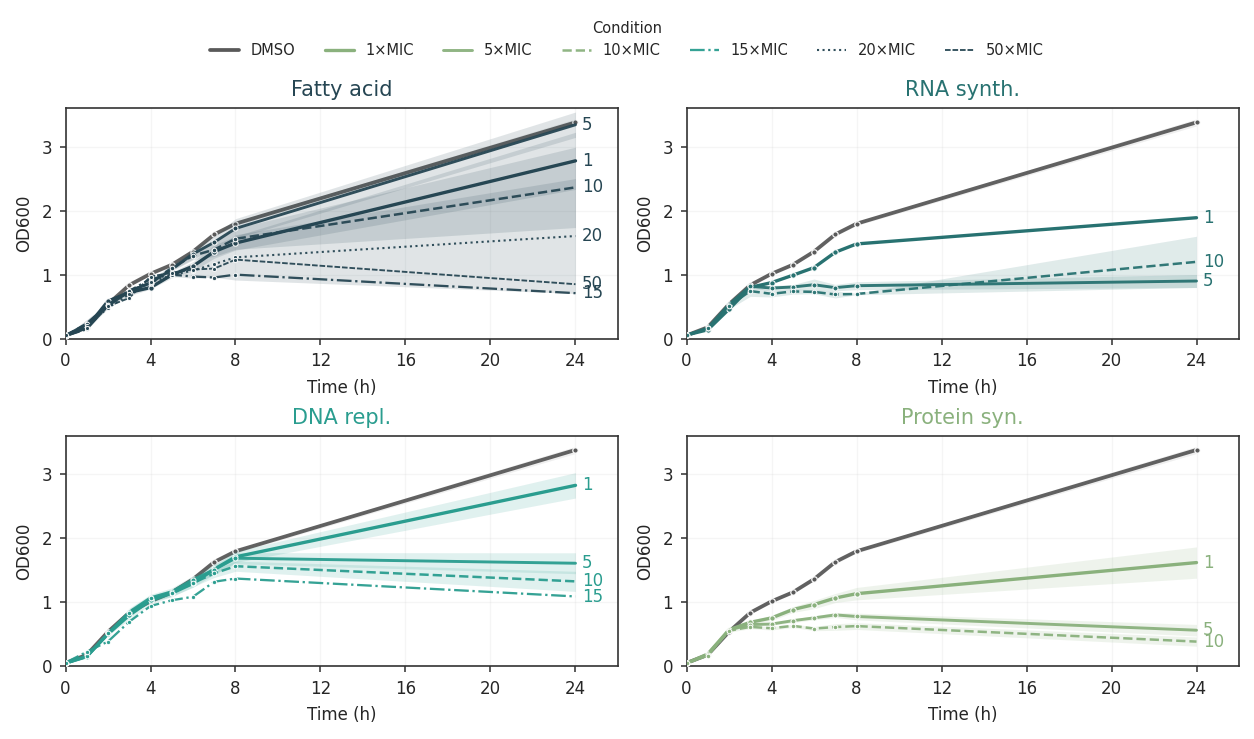

In [ ]:
moas = ["Fatty acid","RNA synth.","DNA repl.","Protein syn."]
fig, axes = plot_growth_facets(
    growth_clean_long,
    moas_to_show=moas,
    ncols=2,             # → 2×2 grid
    col_width=4.2,       # width per column; total width = 2*4.2 = 8.4"
    row_height=2.4,
    ymax=3.6,
    include_dmso_overlay=True,
    savepath="figures/growth_moa_panels_main"
)


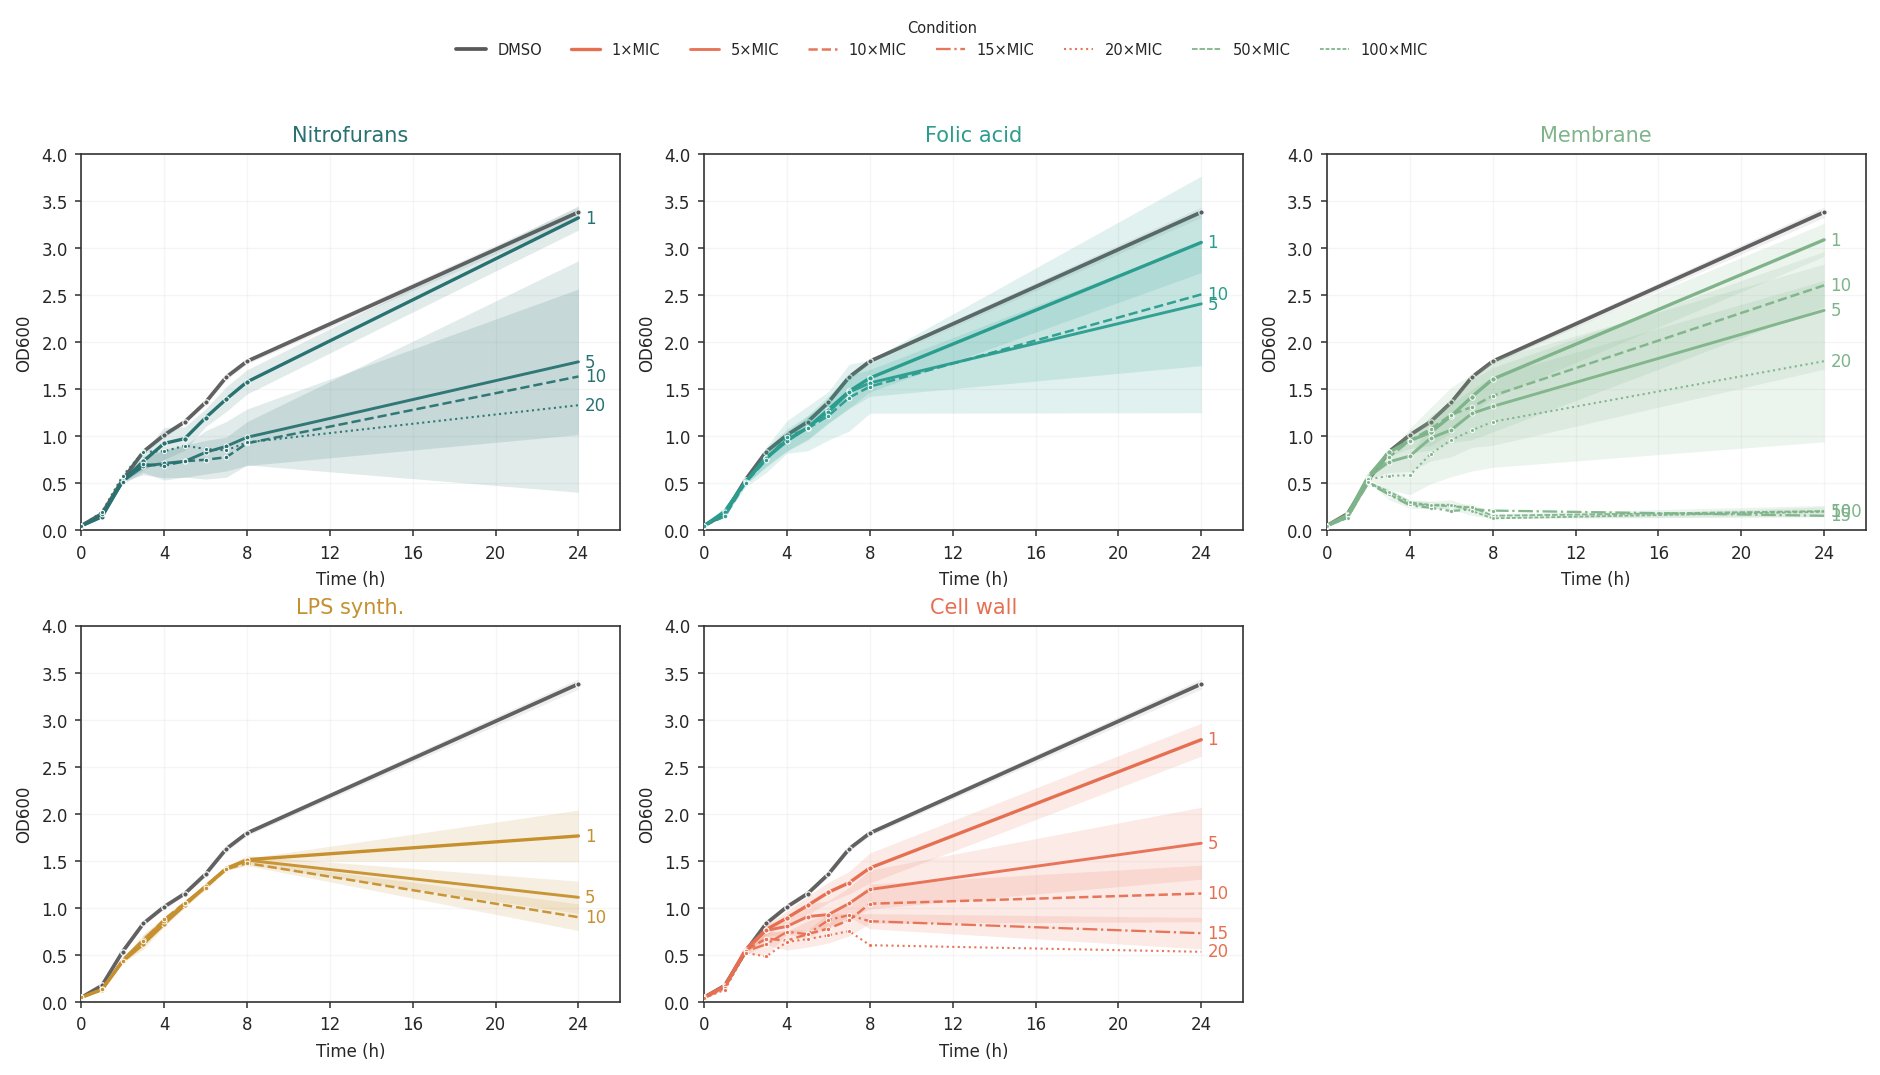

In [61]:
ext_moas = [m for m in MOA_ORDER_FIXED if m in ["Nitrofurans", "Folic acid", "Membrane", "LPS synth.", "Cell wall"]]
FIG_DIR = set_save_dir(REPO_ROOT, "ext_figures")
fig, axes = plot_growth_facets(
    growth_clean_long,
    moas_to_show=ext_moas,
    ncols=3,
    col_width=4.2,
    row_height=3.5,
    ymax=4,
    include_dmso_overlay=True,
    savepath="gc_ex_figure"
)
FIG_DIR = set_save_dir(REPO_ROOT, FIGURE_ID)
